In [29]:
from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 

In [2]:
BASE_PATH = Path.cwd().parent
DATA_DIR = BASE_PATH / "datasets" / "molecules_v1.csv"

In [3]:
pandas_dataframe = pd.read_csv(DATA_DIR)

In [4]:
pandas_dataframe.head()

,molecule_id,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
0,MOL_00000,218.543053,1.149084,74.728164,3,0,4.0,1,313.716356
1,MOL_00001,477.821438,1.787485,66.582419,5,7,0.0,1,60.045075
2,MOL_00002,379.397274,4.836379,35.230783,4,5,9.0,4,-38.137203
3,MOL_00003,319.396318,0.720035,121.453334,4,1,9.0,4,341.276184
4,MOL_00004,120.208388,4.957197,95.324832,3,3,2.0,4,375.938048


In [5]:
pandas_dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   molecule_id       5000 non-null   str    
 1   molecular_weight  5000 non-null   float64
 2   logP              4856 non-null   float64
 3   TPSA              4859 non-null   float64
 4   HBD               5000 non-null   int64  
 5   HBA               5000 non-null   int64  
 6   rotatable_bonds   4836 non-null   float64
 7   aromatic_rings    5000 non-null   int64  
 8   boiling_point_c   5000 non-null   float64
dtypes: float64(5), int64(3), str(1)
memory usage: 395.6 KB


In [6]:
pandas_dataframe.describe()

,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
count,5000.000000,4856.000000,4859.000000,5000.000000,5000.000000,4836.000000,5000.000000,5000.000000
mean,273.574396,1.932696,100.234569,2.466200,4.459600,7.119934,2.035000,200.808561
std,130.335143,2.289981,58.183146,1.713547,2.839574,4.264144,1.412435,164.571761
min,50.005236,-1.999577,0.031549,0.000000,0.000000,0.000000,0.000000,-61.687903
25%,159.738263,-0.029369,49.113763,1.000000,2.000000,4.000000,1.000000,60.333307
50%,275.003882,1.889719,99.630144,2.000000,4.000000,7.000000,2.000000,259.251796
75%,386.645388,3.877379,151.955899,4.000000,7.000000,11.000000,3.000000,356.004512
max,499.872953,5.996042,199.961029,5.000000,9.000000,14.000000,4.000000,411.545366


In [7]:
pandas_dataframe.isnull().sum()

molecule_id           0
molecular_weight      0
logP                144
TPSA                141
HBD                   0
HBA                   0
rotatable_bonds     164
aromatic_rings        0
boiling_point_c       0
dtype: int64

In [8]:
pandas_dataframe.duplicated().sum()

np.int64(0)

In [9]:
len(pandas_dataframe['molecule_id'].unique())

5000

In [10]:
pandas_dataframe.duplicated().sum()

np.int64(0)

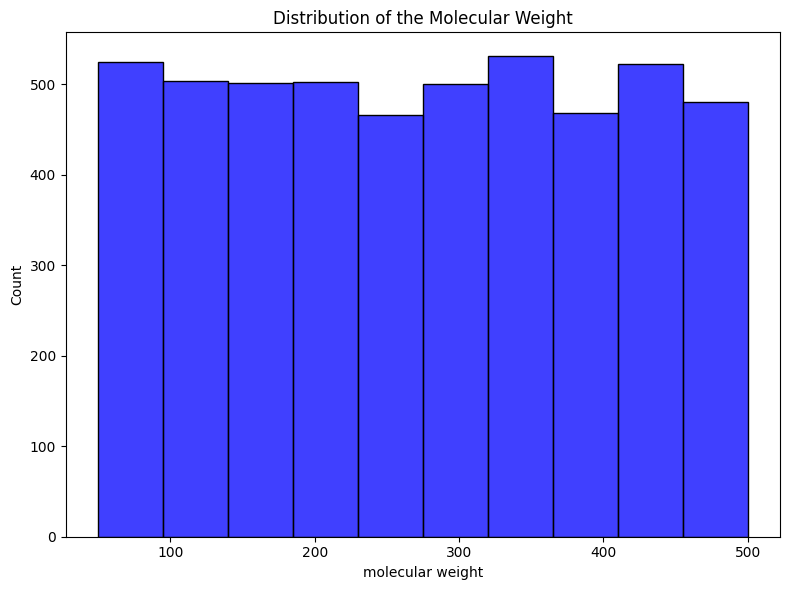

In [11]:
# the distribution of the moleculat weight column
plt.figure(figsize=(8, 6))
sns.histplot(data=pandas_dataframe, x="molecular_weight", bins=10, color='blue')
plt.title("Distribution of the Molecular Weight")
plt.xlabel("molecular weight")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [12]:
pandas_dataframe[pandas_dataframe['logP'] < 0]

,molecule_id,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
5,MOL_00005,120.197534,-1.294925,173.140198,3,3,12.0,2,246.945472
8,MOL_00008,320.501755,-0.545459,152.589776,5,4,5.0,4,368.578327
14,MOL_00014,131.821235,-0.428104,100.641883,0,0,4.0,3,370.804519
15,MOL_00015,132.532029,-0.306033,2.815933,4,6,NaN,4,-42.883656
16,MOL_00016,186.909009,-1.668021,1.391517,0,6,14.0,0,-37.685025
...,...,...,...,...,...,...,...,...,...
4973,MOL_04973,368.275510,-1.516508,32.569315,5,4,4.0,0,-39.803221
4975,MOL_04975,251.026911,-0.510040,111.763447,1,7,14.0,4,357.348786
4988,MOL_04988,379.062765,-1.732656,133.551205,4,1,9.0,0,316.912188
4994,MOL_04994,80.798319,-1.003086,151.661143,2,4,8.0,3,275.421090


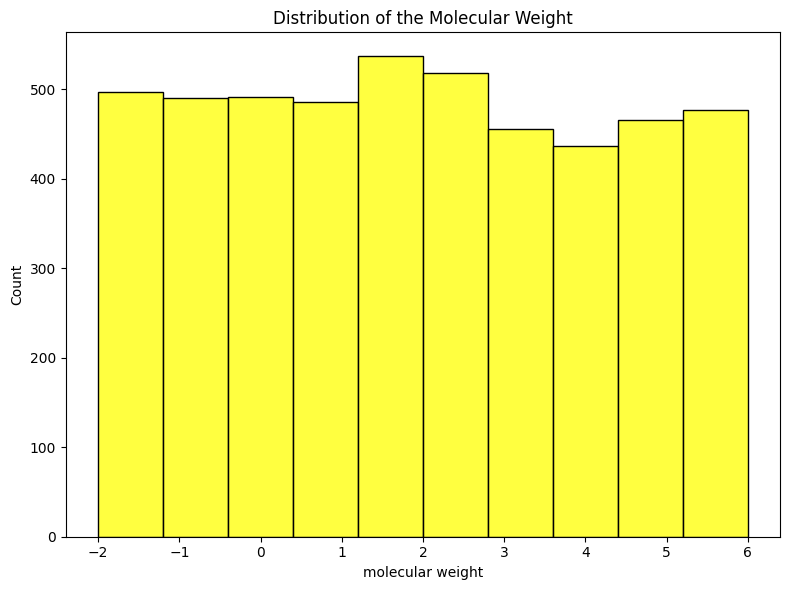

In [13]:
# distribution of thr lop column
plt.figure(figsize=(8, 6))
sns.histplot(data=pandas_dataframe, x="logP", bins=10, color='yellow')
plt.title("Distribution of the Molecular Weight")
plt.xlabel("molecular weight")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [14]:
missing_percentage_logp = (pandas_dataframe['logP'].isnull().sum() / len(pandas_dataframe)) * 100
missing_percentage_tpsa = (pandas_dataframe['TPSA'].isnull().sum() / len(pandas_dataframe)) * 100
print(missing_percentage_logp)
print(missing_percentage_tpsa)

2.88
2.82


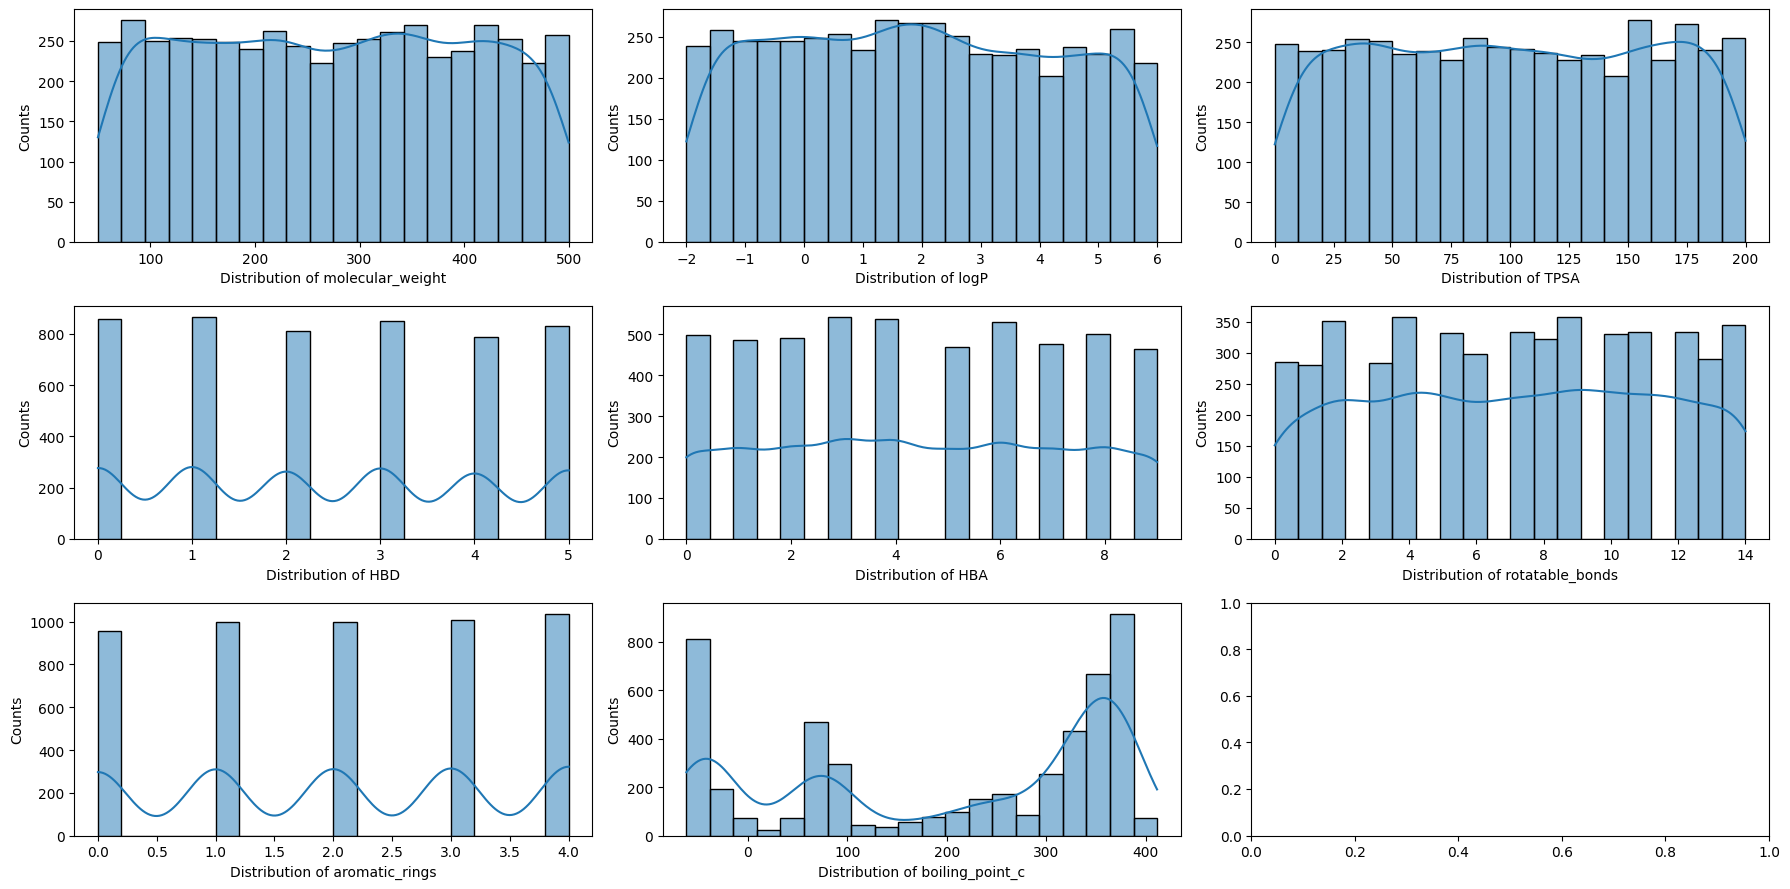

In [15]:
# check for negetive entry 
numerical_columns = pandas_dataframe.select_dtypes(include=('number'))

import math
n_rows = math.ceil(8 / 3)
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(numerical_columns):
    sns.histplot(data=pandas_dataframe, x=col, bins=20, kde=True, ax=axes[i])
    axes[i].set_xlabel(f"Distribution of {col}")
    axes[i].set_ylabel("Counts")
plt.tight_layout()
plt.show()



In [16]:
pandas_dataframe['HBD'].value_counts()

HBD
1    866
0    858
3    849
5    830
2    810
4    787
Name: count, dtype: int64

In [17]:
pandas_dataframe["HBA"].value_counts()

HBA
3    543
4    538
6    531
8    500
0    499
2    492
1    487
7    477
5    469
9    464
Name: count, dtype: int64

In [18]:
pandas_dataframe['rotatable_bonds'].value_counts(ascending=True)

rotatable_bonds
1.0     280
3.0     284
0.0     285
13.0    290
6.0     298
8.0     322
10.0    331
5.0     332
12.0    333
7.0     334
11.0    334
14.0    345
2.0     352
4.0     358
9.0     358
Name: count, dtype: int64

In [19]:
pandas_dataframe["aromatic_rings"].value_counts()

aromatic_rings
4    1037
3    1010
2    1000
1     997
0     956
Name: count, dtype: int64

In [20]:
display(pandas_dataframe.sample(20))

,molecule_id,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
615,MOL_00615,464.392580,4.710715,102.259149,3,8,13.0,0,91.859182
1996,MOL_01996,480.476579,3.336295,174.733731,5,2,13.0,0,337.876539
3567,MOL_03567,350.245552,5.199276,91.176518,1,1,14.0,3,81.563379
2138,MOL_02138,134.335375,3.352428,20.516912,0,7,5.0,4,-40.184390
4738,MOL_04738,218.671216,0.494221,173.774159,1,9,0.0,3,355.492394
4203,MOL_04203,483.565976,1.810706,162.388450,4,6,12.0,0,329.191281
419,MOL_00419,388.568538,0.565869,111.860374,0,6,0.0,4,61.260412
26,MOL_00026,139.853202,0.071234,182.445924,2,8,14.0,4,197.821392
1331,MOL_01331,373.640800,3.737452,28.057003,4,0,8.0,2,-37.924730
4293,MOL_04293,458.608345,2.520590,13.027448,5,9,8.0,4,-35.108220


In [21]:
negetive_boiling_point = pandas_dataframe[pandas_dataframe['boiling_point_c'] < 0]
len(negetive_boiling_point)
display(negetive_boiling_point.sample(20))

,molecule_id,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
1702,MOL_01702,190.317260,1.031647,NaN,1,6,3.0,4,-47.477282
120,MOL_00120,413.348070,0.544317,NaN,4,4,6.0,0,-7.513023
773,MOL_00773,228.779281,3.755105,40.454636,5,0,10.0,2,-27.426804
3259,MOL_03259,453.053650,4.348299,37.282769,1,1,12.0,1,-55.703457
1747,MOL_01747,166.915944,-1.407401,8.556654,4,6,10.0,1,-38.096203
1896,MOL_01896,327.193453,4.453662,13.405616,2,1,13.0,1,-45.506201
2616,MOL_02616,212.105263,0.564289,16.340792,4,4,14.0,1,-50.024892
1800,MOL_01800,480.425629,-1.543207,35.427091,0,7,5.0,0,-49.652937
756,MOL_00756,329.032740,3.045082,36.530324,3,5,8.0,3,-37.016953
212,MOL_00212,343.382567,0.609764,23.731141,0,6,8.0,1,-46.545353


In [22]:
groupby_data = negetive_boiling_point.groupby("HBA")['boiling_point_c'].count()
display(groupby_data)

HBA
0     95
1    112
2     89
3    111
4    113
5    101
6    116
7    113
8    116
9    104
Name: boiling_point_c, dtype: int64

In [23]:
(len(negetive_boiling_point) / len(pandas_dataframe)) * 100

21.4

In [31]:
# create a function to clean the data 
import math
molecular_regression_data = pandas_dataframe.copy()
def clean_data(data):
    # fill the numerical cols with the median
    data['logP'] = data['logP'].fillna(data['logP'].median())
    data['TPSA'] = data['TPSA'].fillna(data['TPSA'].median())
    data['rotatable_bonds'] = np.floor(data['rotatable_bonds'].fillna(data['rotatable_bonds'].median()))

    return data

cleaned_data = clean_data(molecular_regression_data)
print(cleaned_data.head())

  molecule_id  molecular_weight      logP        TPSA  HBD  HBA  \
0   MOL_00000        218.543053  1.149084   74.728164    3    0   
1   MOL_00001        477.821438  1.787485   66.582419    5    7   
2   MOL_00002        379.397274  4.836379   35.230783    4    5   
3   MOL_00003        319.396318  0.720035  121.453334    4    1   
4   MOL_00004        120.208388  4.957197   95.324832    3    3   

   rotatable_bonds  aromatic_rings  boiling_point_c  
0              4.0               1       313.716356  
1              0.0               1        60.045075  
2              9.0               4       -38.137203  
3              9.0               4       341.276184  
4              2.0               4       375.938048  


In [33]:
cleaned_data.isna().sum()

molecule_id         0
molecular_weight    0
logP                0
TPSA                0
HBD                 0
HBA                 0
rotatable_bonds     0
aromatic_rings      0
boiling_point_c     0
dtype: int64

In [37]:
cleaned_data.to_csv("../datasets/molecules_v2.csv", index=False)

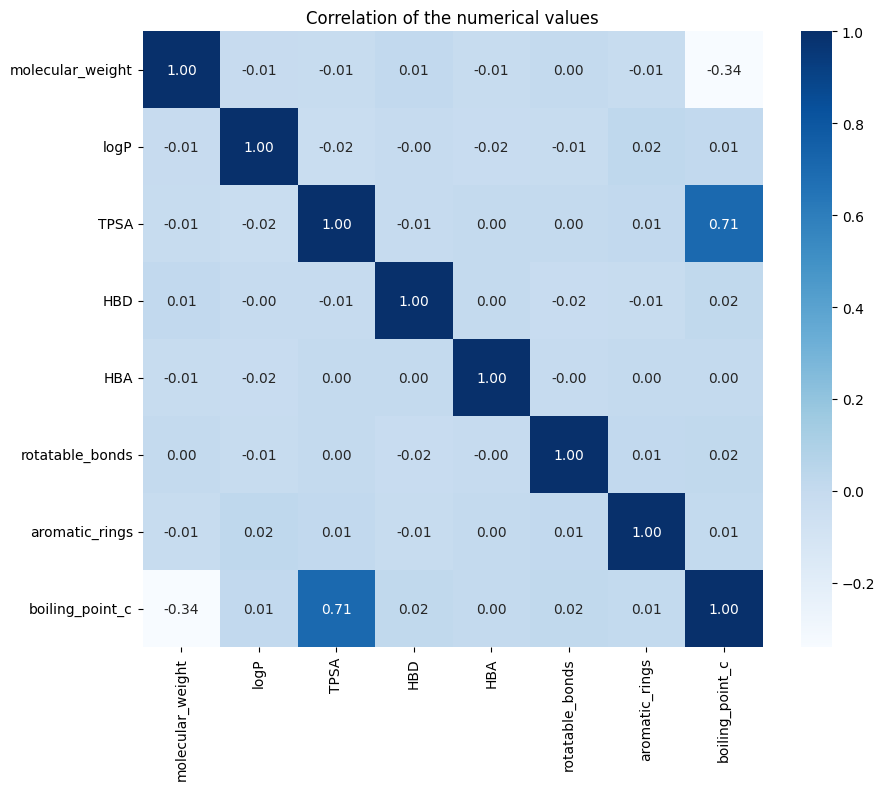

In [40]:
# check for correlation 
correlation_data = cleaned_data.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(data=correlation_data, fmt=".2f", annot=True, cmap="Blues")
plt.title("Correlation of the numerical values")
plt.show()